
0: 384x640 2 License_Plates, 191.6ms
Speed: 0.6ms preprocess, 191.6ms inference, 0.3ms postprocess per image at shape (1, 3, 384, 640)


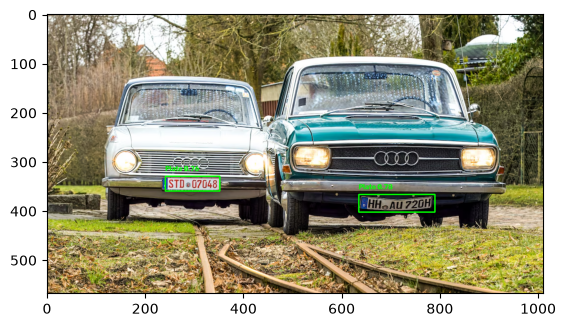

[(635, 366, 790, 402), (241, 329, 352, 359)]


In [6]:
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

# https://huggingface.co/morsetechlab/yolov11-license-plate-detection
weights = hf_hub_download("morsetechlab/yolov11-license-plate-detection", "license-plate-finetune-v1x.pt")
model = YOLO(weights)

license_plates = []

frame = cv2.imread('auto2.avif')
frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

pred = model.predict(frame)

for result in pred:
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        conf = box.conf[0].item()
        label = f"Plate {conf:.2f}"
        
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(frame, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

        if conf > THRESHOLD:
            license_plates.append((x1, y1, x2, y2))
plt.imshow(frame)
plt.show()
print(license_plates)

2026-10-26 22:13:07.811 Python[63831:9185092] 2026-10-26 22:13:07.811450 [W:onnxruntime:, coreml_execution_provider.cc:141 GetCapability] CoreMLExecutionProvider::GetCapability, number of partitions supported by CoreML: 53 number of nodes in the graph: 431 number of nodes supported by CoreML: 282


[PlatePrediction(plate='HHAU720H', char_probs=None, region='Germany', region_prob=None)]


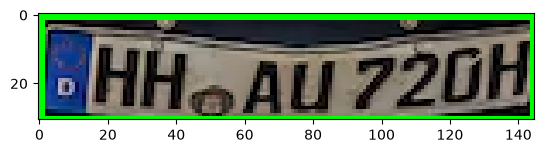

[PlatePrediction(plate='STD07048', char_probs=None, region='Germany', region_prob=None)]


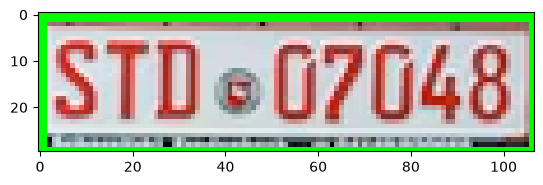

In [3]:
from fast_plate_ocr import LicensePlateRecognizer

# https://github.com/ankandrew/fast-plate-ocr
m = LicensePlateRecognizer('cct-s-v2-global-model')

for (x1, y1, x2, y2) in license_plates:
    print(m.run(frame[y1:y2, x1:x2, :]))
    plt.imshow(frame[y1:y2, x1:x2, :])
    plt.show()